# The epidemic problem, the baked traces and a first run of the engine

- **Level:** 1, Fundamentals
- **Prerequisites:** none, this is the entry notebook
- **Reading time:** about 15 minutes

## Objectives

By the end of this notebook you can:

- say what problem the example product models and which data it commits;
- read an index, a manifest and a trace from `data/derived/`;
- write the equations of the model the engine integrates;
- run the engine of `data-pipeline/pipeline/` on one case and check that it reproduces the committed trace.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with the exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

This example product publishes no package of its own: its method lives in `data-pipeline/pipeline/`, so the notebook imports that code by its path. A product imports its own PyPI package instead (`pip install <package>==<version>`).

The next cell imports the tools and prints their versions.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json

import numpy as np
import matplotlib.pyplot as plt

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


The engine is not an installed package: this cell puts `data-pipeline/` on the import path and imports the engine (`simulate`) and the parameter record (`SIRParams`). Importing it, never copying it, keeps one engine for the pipeline, the tests and these notebooks.

In [2]:
# The notebook sits three folders below the repository root; the pipeline's modules are imported by their path
import sys
from pathlib import Path

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.sir import simulate
from pipeline.io.schema import SIRParams

print(simulate.__module__, SIRParams.__module__)

pipeline.model.sir pipeline.io.schema


## Data

The problem: how does an epidemic in a closed population unfold, and when does it take off at all? The product answers with five cases (four regimes and one control) that its pipeline bakes once and commits, so that the web and these notebooks read the same artifacts.

- Owner: this repository (the product template's example), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Licence class: synthetic data produced by the pipeline from the parameters in each manifest (`real_or_synthetic` is `synthetic`); no third-party dataset, so no dataset licence applies, and the repository's MIT licence covers the artifacts.
- Files read: `data/derived/manifests/index.json`, `data/derived/manifests/<case>.json` and `data/derived/<case>/trace.json`.

The next cell defines two small readers and lists the cases of the index.

In [3]:
# Two readers of the committed artifacts: a missing file stops the notebook and names its path
def read_json(relative):
    return json.loads((ROOT / "data" / "derived" / relative).read_text(encoding="utf-8"))


def params_of(case_id):
    p = read_json(f"manifests/{case_id}.json")["params"]
    return SIRParams(case_id, p["beta"], p["gamma"], p["N"], p["I0"], p["days"])


CASES = [c["case_id"] for c in read_json("manifests/index.json")["cases"]]
OUTBREAKS = [c for c in CASES if c.startswith("EX")]
SUPERCRITICAL = [c for c in OUTBREAKS if params_of(c).beta > params_of(c).gamma]
print(CASES)
print("cases that can take off:", SUPERCRITICAL)

['CTRL_degenerate', 'EX01_subcritical', 'EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']
cases that can take off: ['EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']


The manifest of a case holds its parameters, its seed, the engine that produced it and the ranges its results must fall in; the trace holds the decimated trajectory (at most 200 points) and a summary. This cell loads the epidemic case (`EX02_epidemic`) and prints the fields a reader needs first.

In [4]:
# Load the manifest and the trace of the epidemic case and print what they hold
manifest = read_json("manifests/EX02_epidemic.json")
trace = read_json("EX02_epidemic/trace.json")

print("parameters:", manifest["params"])
print("seed:", manifest["seed"], "| engine:", manifest["engine"]["model"])
print("trace points:", len(trace["t"]), "| days covered:", trace["t"][-1])
print("summary:", trace["summary"])

parameters: {'beta': 0.55, 'gamma': 0.2, 'N': 100000.0, 'I0': 50.0, 'days': 160}
seed: 42 | engine: SIR, forward Euler
trace points: 200 | days covered: 160.0
summary: {'peak_I': 27345.24, 't_peak': 24.25, 'attack_rate': 0.9237}


The trace is three curves over time: susceptible (S), infected (I) and recovered (R) people. This cell draws them, so the shape of the epidemic is visible before any equation.

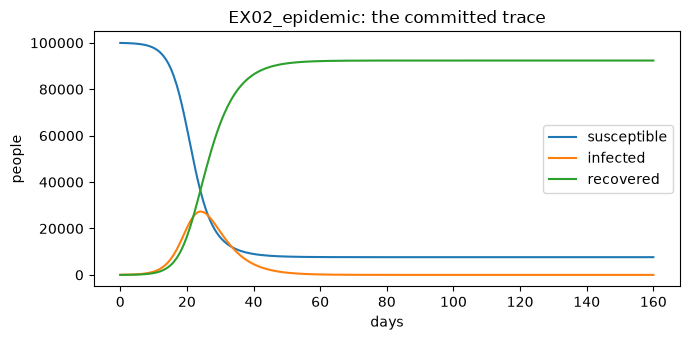

In [5]:
# Draw S, I and R of the committed trace against time
fig, ax = plt.subplots(figsize=(7, 3.5))
for key, label in (("S", "susceptible"), ("I", "infected"), ("R", "recovered")):
    ax.plot(trace["t"], trace[key], label=label)
ax.set_xlabel("days")
ax.set_ylabel("people")
ax.set_title("EX02_epidemic: the committed trace")
ax.legend()
fig.tight_layout()
plt.show()

## Method

The model is the closed SIR system of Kermack and McKendrick (1927), with the textbook assumptions the survey of Hethcote (2000) states (closed population, homogeneous mixing, deterministic):

$$\frac{dS}{dt} = -\beta \frac{S I}{N}, \qquad \frac{dI}{dt} = \beta \frac{S I}{N} - \gamma I, \qquad \frac{dR}{dt} = \gamma I$$

where $\beta$ is the contact rate, $\gamma$ the recovery rate and $N$ the population. The ratio $R_0 = \beta / \gamma$ decides whether an epidemic takes off (notebook 02 of this topic).

The engine integrates the system with Forward Euler at a quarter-day step (Hairer, Norsett and Wanner, 1993). This cell runs it, through the pipeline, on the parameters of the manifest.

In [6]:
# Run the pipeline's engine on the manifest's parameters (one call, one case)
params = params_of("EX02_epidemic")
run = simulate(params)

print("R0 = beta / gamma =", round(params.beta / params.gamma, 2))
print("steps taken:", len(run.t) - 1)
print("peak infected:", round(run.peak_I), "on day", run.t_peak)
print("attack rate:", round(run.attack_rate, 4))

R0 = beta / gamma = 2.75
steps taken: 640
peak infected: 27345 on day 24.25
attack rate: 0.9237


## Results

The committed trace keeps 200 points of the 641 the engine computes, rounded to two decimals. This cell picks the engine's values at the trace's times and measures the largest difference per compartment.

In [7]:
# Compare the fresh run with the committed trace at the trace's times (the step is 0.25 days)
index = [round(t / 0.25) for t in trace["t"]]
for key in ("S", "I", "R"):
    fresh = np.array(getattr(run, key))[index]
    print(key, "largest difference, in people:", float(np.max(np.abs(fresh - np.array(trace[key])))))
print("summary matches:", round(run.attack_rate, 4) == trace["summary"]["attack_rate"])

S largest difference, in people: 0.0049340308769387775
I largest difference, in people: 0.004997702378549462
R largest difference, in people: 0.004988331609638408
summary matches: True


The differences are at most half a hundredth of a person, which is the rounding of the committed trace: the artifact is exactly what the engine produces. The figure above shows the usual shape of an epidemic: the infected curve rises to one peak and falls as the susceptible pool is used up. What this notebook does not show is why the peak is where it is, or how close the result is to the exact answer; the next notebook takes the method apart for that.

## Summary

- The product's data are five baked cases, read from `data/derived/`, never recomputed by the page.
- The engine is the pipeline's, imported by path; it reproduces the committed trace to its rounding.
- Next: notebook 02 of this topic runs the method step by step and checks it against an exact answer.

## References

- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Hethcote, H. W. (2000). The mathematics of infectious diseases. SIAM Review. https://doi.org/10.1137/S0036144500371907
- Hairer, E., Norsett, S. P. and Wanner, G. (1993). Solving Ordinary Differential Equations I: Nonstiff Problems. Springer. https://doi.org/10.1007/978-3-540-78862-1
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- The engine and the cases of this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).

What each work is credited with is what the research basis of the SDD (`docs/design/SDD.md`) records; the text of their pages was not re-read, only their Crossref records.